**<font color='yellow' size="6">Esophageal Cancer Classification Using YOLOV8 for SAVE images</font><br>**

In [1]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
# Directory for your save data
DATA_DIR_save_reference = '/content/drive/MyDrive/Arvind/Arvind/combined_split'

In [3]:
from IPython.display import Image, display

In [4]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.0/879.0 kB 61.4 MB/s eta 0:00:00


<font color='yellow' size='4'>SAVE images Training for YOLOv8x and YOLOv8n for 300 epochs with 100 as a pause value </font>

In [5]:
import os
from ultralytics import YOLO

# Directory for your WLI data
DATA_DIR_SAVE = '/content/drive/MyDrive/Arvind/Arvind/combined_split'

# List of YOLOv8 model versions you want to try
model_versions = ["yolov8x-cls.pt", "yolov8n-cls.pt"]  # YOLOv8 'x' and 'n' versions

# Initialize variables to track the best model
best_model = None
best_accuracy = 0

# Train each model version
for model_version in model_versions:
    model = YOLO(model_version)  # Load the pretrained model

    # Train in increments of 100 epochs, up to 300 epochs
    for i in range(0, 300, 100):
        # Specify a unique directory for each 100-epoch segment
        run_name = f"train_{model_version.split('.')[0]}_{i+100}_epochs"
        results = model.train(
            data=DATA_DIR_SAVE,
            epochs=300,           # Train for 100 epochs
            imgsz=640,            # Image size
            batch=16,             # Batch size
            augment=False,        # Enable augmentation
            flipud=0.5,           # Vertical flip with 50% probability
            fliplr=0.5,           # Horizontal flip with 50% probability
            degrees=10,           # Rotate images by up to 10 degrees
            scale=0.5,            # Scale images by up to 50%
            translate=0.1,        # Translate images by 10% in x and y directions
            lr0=0.001,            # Initial learning rate
            save=True,            # Save the model checkpoints
            project="runs",       # Save directory
            name=run_name         # Unique name for the run
        )

        # Evaluate the model on the validation set
        val_results = model.val(data=DATA_DIR_SAVE, imgsz=640, batch=16)

        # Track accuracy or any other metric
        current_accuracy = val_results.top1  # Access accuracy directly from val_results
        # You can also access top5 accuracy using val_results.top5

        if current_accuracy > best_accuracy:
            best_accuracy = current_accuracy
            best_model = model_version

        # Log the results
        print(f"Model: {model_version}, Epochs: {i + 100}, Accuracy: {current_accuracy}")

# Output the best model after all training
print(f"Best model: {best_model} with accuracy: {best_accuracy}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 110M/110M [00:02<00:00, 40.2MB/s]


Ultralytics 8.3.27 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
engine/trainer: task=classify, mode=train, model=yolov8x-cls.pt, data=/content/drive/MyDrive/Arvind/Arvind/combined_split, epochs=300, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=runs, name=train_yolov8x-cls_100_epochs, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=

100%|██████████| 5.35M/5.35M [00:00<00:00, 374MB/s]


AMP: checks passed ✅


train: Scanning /content/drive/MyDrive/Arvind/Arvind/combined_split/train... 2880 images, 0 corrupt: 100%|██████████| 2880/2880 [00:00<?, ?it/s]
val: Scanning /content/drive/MyDrive/Arvind/Arvind/combined_split/test... 320 images, 0 corrupt: 100%|██████████| 320/320 [00:00<?, ?it/s]


... (901 outputs left out)


300 epochs completed in 2.236 hours.
Optimizer stripped from runs/train_yolov8x-cls_100_epochs/weights/last.pt, 112.5MB
Optimizer stripped from runs/train_yolov8x-cls_100_epochs/weights/best.pt, 112.5MB

Validating runs/train_yolov8x-cls_100_epochs/weights/best.pt...
Ultralytics 8.3.27 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv8x-cls summary (fused): 133 layers, 56,141,134 parameters, 0 gradients, 153.8 GFLOPs
WARNING ⚠️ Dataset 'split=val' not found, using 'split=test' instead.
train: /content/drive/MyDrive/Arvind/Arvind/combined_split/train... found 2880 images in 14 classes ✅ 
val: None...
test: /content/drive/MyDrive/Arvind/Arvind/combined_split/test... found 320 images in 14 classes ✅ 


               classes   top1_acc   top5_acc: 100%|██████████| 10/10 [00:01<00:00,  9.46it/s]


                   all      0.906          1
Speed: 0.5ms preprocess, 2.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/train_yolov8x-cls_100_epochs
Ultralytics 8.3.27 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv8x-cls summary (fused): 133 layers, 56,141,134 parameters, 0 gradients, 153.8 GFLOPs
WARNING ⚠️ Dataset 'split=val' not found, using 'split=test' instead.
train: /content/drive/MyDrive/Arvind/Arvind/combined_split/train... found 2880 images in 14 classes ✅ 
val: None...
test: /content/drive/MyDrive/Arvind/Arvind/combined_split/test... found 320 images in 14 classes ✅ 


TypeError: expected str, bytes or os.PathLike object, not NoneType

In [6]:
!scp -r /content/runs  '/content/drive/MyDrive/Arvind'

<font color='yellow' size='6'>Validation Accuracy of the 300th epochs</font>

**best.pt for the 300th epochs of YOLOv8x**

In [11]:
!yolo task=classify mode=val model=/content/drive/MyDrive/Arvind/runs/train_yolov8x-cls_100_epochs/weights/best.pt data={DATA_DIR_save_reference}

Ultralytics 8.3.27 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv8x-cls summary (fused): 133 layers, 56,141,134 parameters, 0 gradients, 153.8 GFLOPs
train: /content/drive/MyDrive/Arvind/Arvind/combined_split/train... found 2880 images in 14 classes ✅ 
val: /content/drive/MyDrive/Arvind/Arvind/combined_split/val... found 640 images in 14 classes ✅ 
test: /content/drive/MyDrive/Arvind/Arvind/combined_split/test... found 320 images in 14 classes ✅ 
val: Scanning /content/drive/MyDrive/Arvind/Arvind/combined_split/val... 640 images, 0 corrupt: 100% 640/640 [00:58<00:00, 10.98it/s]
val: New cache created: /content/drive/MyDrive/Arvind/Arvind/combined_split/val.cache
               classes   top1_acc   top5_acc: 100% 40/40 [00:04<00:00,  8.45it/s]
                   all          1          1
Speed: 1.1ms preprocess, 3.5ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val2
💡 Learn more at https://docs.ultralytics.com/mode

**best.pt for the 300th epochs of YOLOv8n**

In [10]:
!yolo task=classify mode=val model=/content/drive/MyDrive/Arvind/runs/train_yolov8n-cls_100_epochs/weights/best.pt data={DATA_DIR_save_reference}

Traceback (most recent call last):
  File "/usr/local/bin/yolo", line 8, in <module>
    sys.exit(entrypoint())
  File "/usr/local/lib/python3.10/dist-packages/ultralytics/cfg/__init__.py", line 797, in entrypoint
    model = YOLO(model, task=task)
  File "/usr/local/lib/python3.10/dist-packages/ultralytics/models/yolo/model.py", line 23, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
  File "/usr/local/lib/python3.10/dist-packages/ultralytics/engine/model.py", line 145, in __init__
    self._load(model, task=task)
  File "/usr/local/lib/python3.10/dist-packages/ultralytics/engine/model.py", line 285, in _load
    self.model, self.ckpt = attempt_load_one_weight(weights)
  File "/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py", line 910, in attempt_load_one_weight
    ckpt, weight = torch_safe_load(weight)  # load ckpt
  File "/usr/local/lib/python3.10/dist-packages/ultralytics/nn/tasks.py", line 837, in torch_safe_load
    ckpt = torch.load(fi

**YOLOv8x**

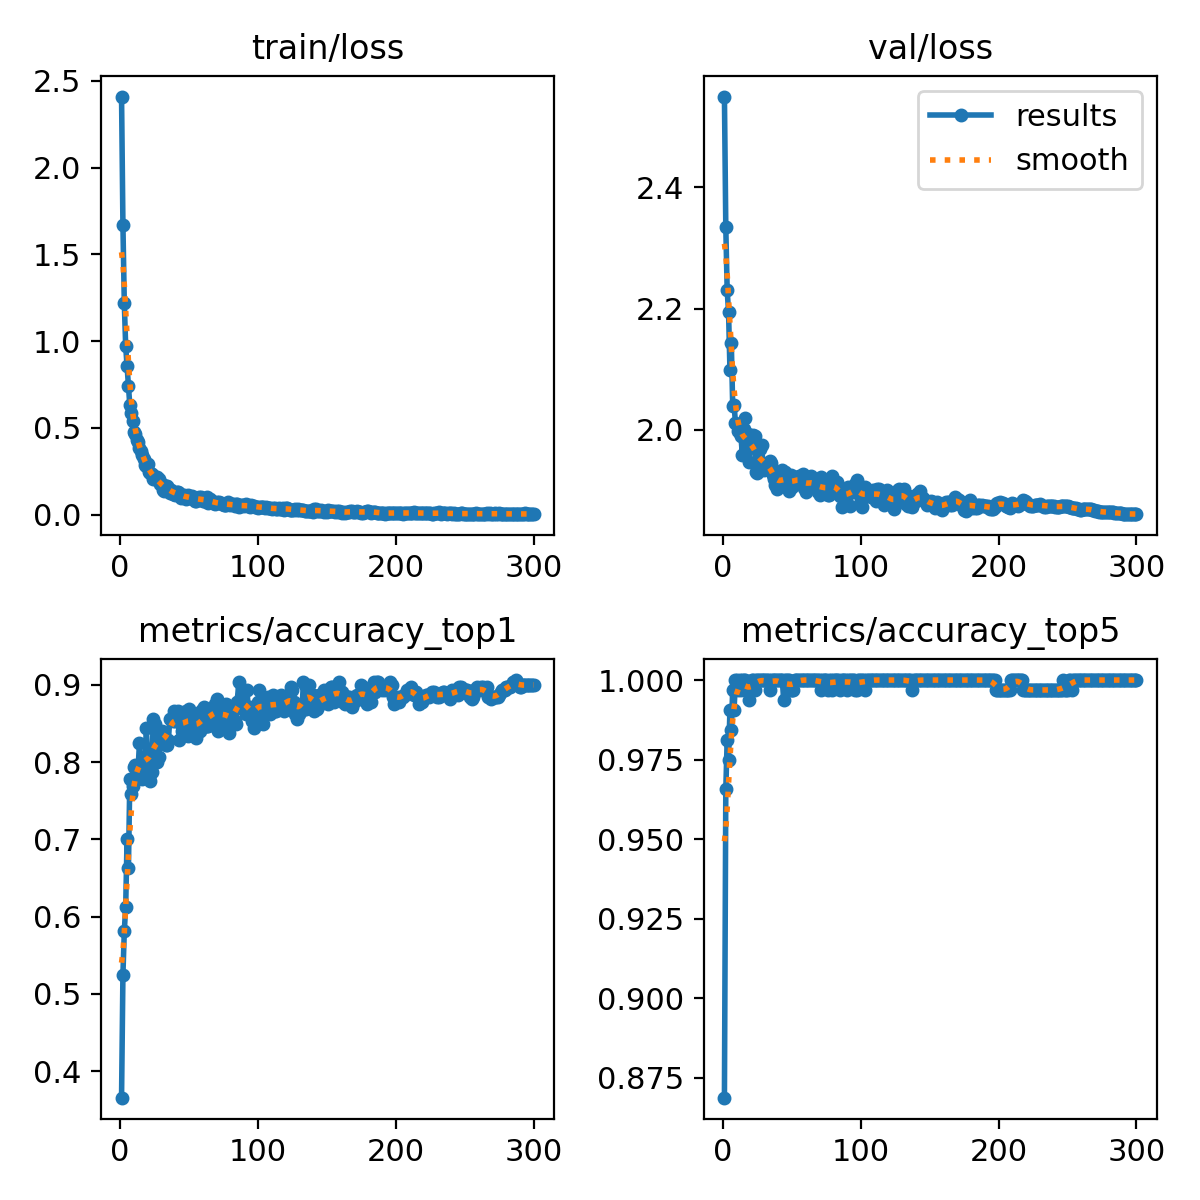

In [14]:
Image(filename='/content/drive/MyDrive/Arvind/runs/train_yolov8x-cls_100_epochs/results.png', width=1000, height=800)

**YOLOv8n**

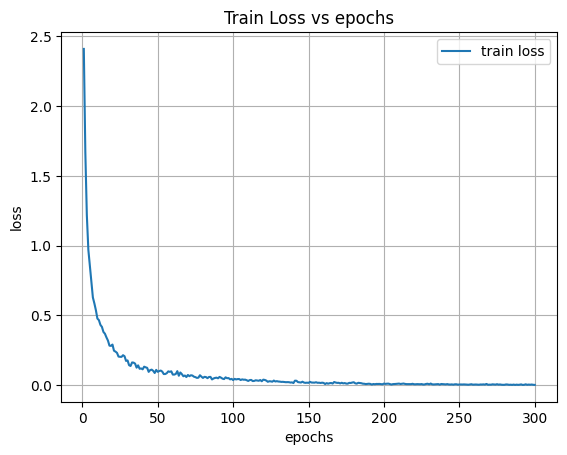

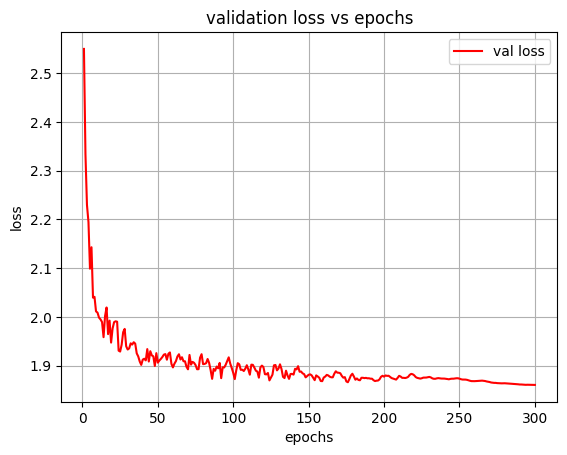

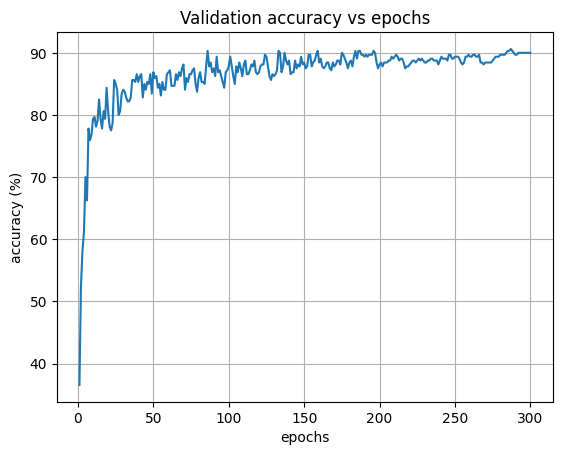

In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt


 #= './runs/classify/train/results.csv'
results_path = '/content/drive/MyDrive/Arvind/runs/train_yolov8x-cls_100_epochs/results.csv'

results = pd.read_csv(results_path)

plt.figure()
plt.plot(results['epoch'], results['train/loss'], label='train loss')
#plt.plot(results['                  epoch'], results['               val/loss'], label='val loss', c='red')
plt.grid()
plt.title('Train Loss vs epochs')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend()


plt.figure()
plt.plot(results['epoch'], results['val/loss'], label='val loss', c='red')
plt.grid()
plt.title('validation loss vs epochs')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend()


plt.figure()
plt.plot(results['epoch'], results['metrics/accuracy_top1'] * 100)
plt.grid()
plt.title('Validation accuracy vs epochs')
plt.ylabel('accuracy (%)')
plt.xlabel('epochs')

plt.show()


<font color='yellow' size='6'>Test Accuracy of 300th epochs </font>

**best.pt for the 300th epochs of YOLOv8x for the test images**

In [19]:
from ultralytics import YOLO

# Load the best model
model_x = YOLO('/content/drive/MyDrive/Arvind/runs/train_yolov8x-cls_100_epochs/weights/best.pt')

# Evaluate on the test dataset
results_x = model_x.val(data='/content/drive/MyDrive/Arvind/Arvind/combined_split', split='test')



Ultralytics 8.3.27 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv8x-cls summary (fused): 133 layers, 56,141,134 parameters, 0 gradients, 153.8 GFLOPs
train: /content/drive/MyDrive/Arvind/Arvind/combined_split/train... found 2880 images in 14 classes ✅ 
val: /content/drive/MyDrive/Arvind/Arvind/combined_split/val... found 640 images in 14 classes ✅ 
test: /content/drive/MyDrive/Arvind/Arvind/combined_split/test... found 320 images in 14 classes ✅ 


test: Scanning /content/drive/MyDrive/Arvind/Arvind/combined_split/test... 320 images, 0 corrupt: 100%|██████████| 320/320 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc: 100%|██████████| 20/20 [00:03<00:00,  5.89it/s]


                   all      0.906          1
Speed: 0.5ms preprocess, 4.0ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val3


**best.pt for the 300th epochs of YOLOv8n for the test images**

In [24]:
from ultralytics import YOLO

# Load the best model
model_n = YOLO('/content/drive/MyDrive/Arvind/runs/train_yolov8x-cls_100_epochs/weights/best.pt')

# Evaluate on the test dataset
results_n = model_n.val(data='/content/drive/MyDrive/Arvind/Arvind/combined_split', split='test')



Ultralytics 8.3.27 🚀 Python-3.10.12 torch-2.5.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv8x-cls summary (fused): 133 layers, 56,141,134 parameters, 0 gradients, 153.8 GFLOPs
train: /content/drive/MyDrive/Arvind/Arvind/combined_split/train... found 2880 images in 14 classes ✅ 
val: /content/drive/MyDrive/Arvind/Arvind/combined_split/val... found 640 images in 14 classes ✅ 
test: /content/drive/MyDrive/Arvind/Arvind/combined_split/test... found 320 images in 14 classes ✅ 


test: Scanning /content/drive/MyDrive/Arvind/Arvind/combined_split/test... 320 images, 0 corrupt: 100%|██████████| 320/320 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc: 100%|██████████| 20/20 [00:02<00:00,  7.28it/s]


                   all      0.906          1
Speed: 0.4ms preprocess, 3.4ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val6


In [26]:
import os
import shutil
from datetime import datetime

# Define source and destination directories
source_dir = '/content/runs'
destination_base_dir = '/content/drive/MyDrive/Arvind/Yolov8/'

# Create a unique destination directory to avoid overwriting
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
destination_dir = os.path.join(destination_base_dir, f'runs_{timestamp}')

# Create the unique directory
os.makedirs(destination_dir, exist_ok=True)

print("Unique destination directory created:", destination_dir)
# Copy the entire 'runs' directory to the new unique directory
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"Files successfully copied to {destination_dir}")
# List files in the destination directory to verify the copy operation
copied_files = os.listdir(destination_dir)
print("Files in the destination directory:", copied_files)


Unique destination directory created: /content/drive/MyDrive/Arvind/Yolov8/runs_20241106_114705
Files successfully copied to /content/drive/MyDrive/Arvind/Yolov8/runs_20241106_114705
Files in the destination directory: ['classify', 'train_yolov8x-cls_100_epochs2', 'train_yolov8x-cls_100_epochs']


**Confusion matrix for test images**

**YOLOv8x**

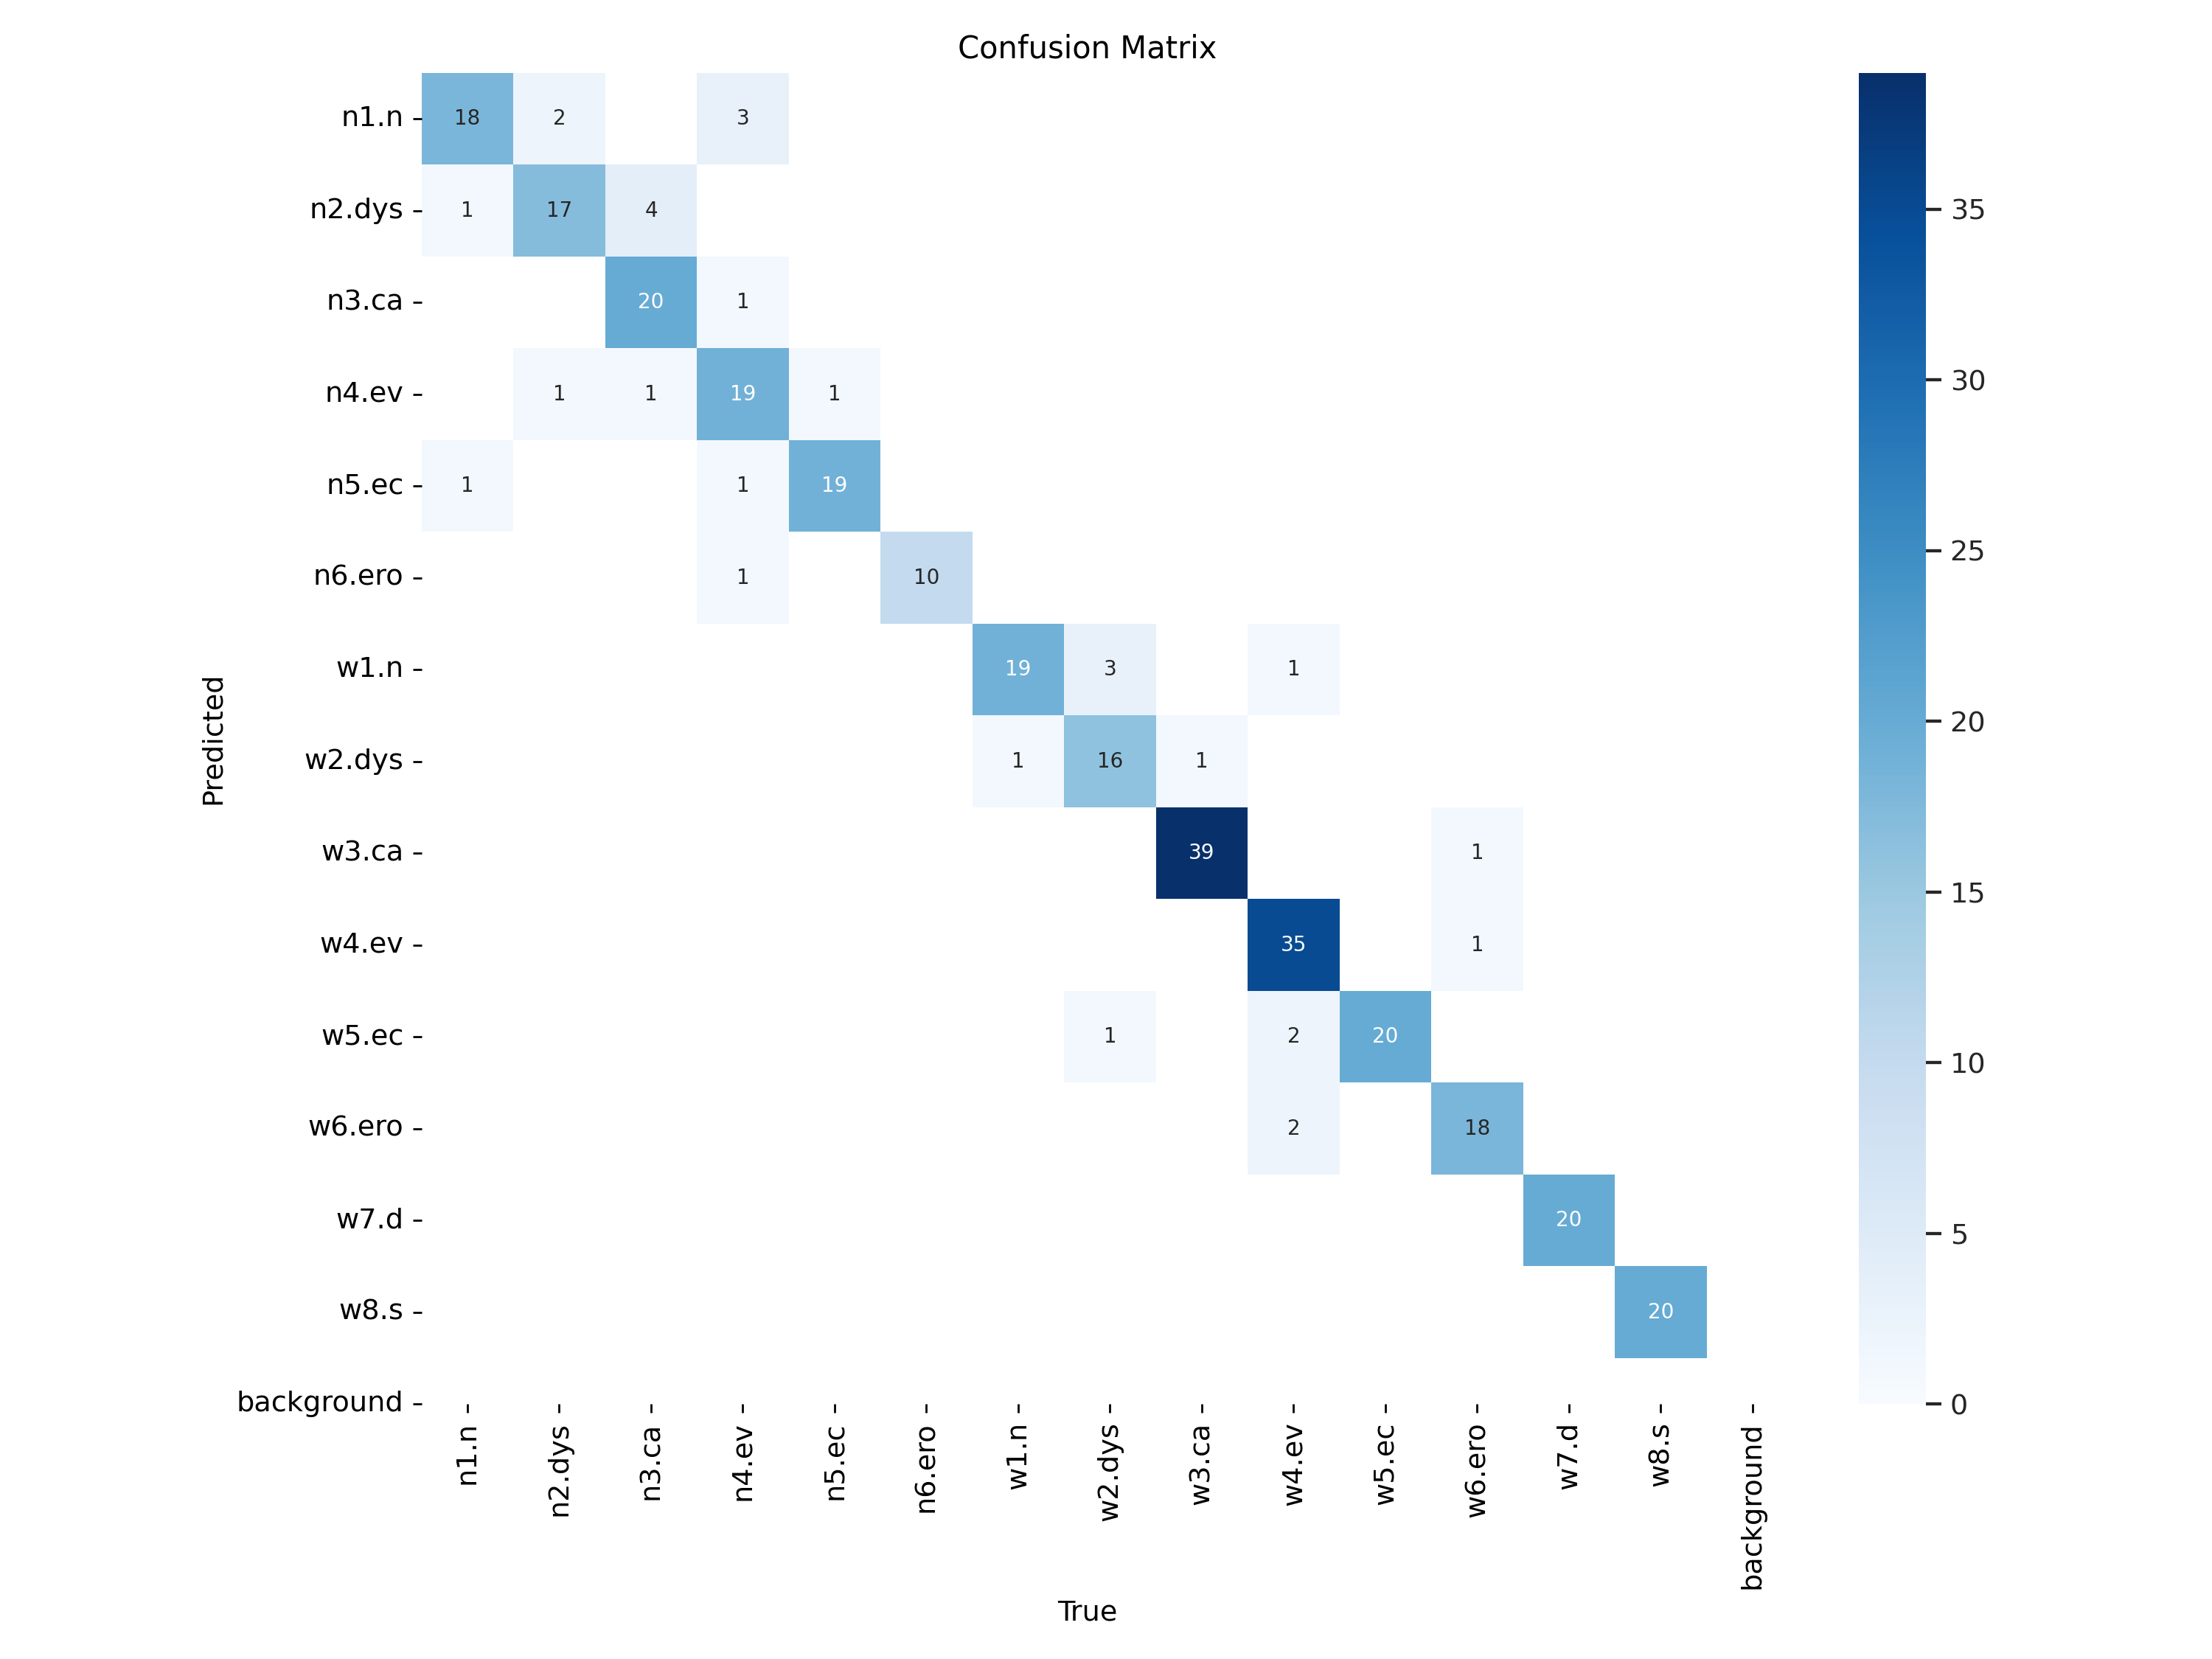

In [28]:
Image(filename='/content/drive/MyDrive/Arvind/Yolov8/Runs/Results/confusion_matrix.png', width=1000, height=700)


**YOLOv8n**

**YOLOv8n Classification report**

In [32]:
from sklearn.metrics import classification_report
confusion_matrix_n = [
    [18, 2, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 17, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 20, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 19, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 0, 0, 1, 19, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 10, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 19, 3, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 1, 16, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 39, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 35, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 20, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 18, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 20, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 20],
]

# Assuming your class names are in this order
class_names = ['n1.n', 'n2.dys', 'n3.ca', 'n4.ev', 'n5.ec', 'n6.ero', 'w1.n', 'w2.dys','w3.ca', 'w4.ev','w5.ec', 'w6.ero', 'w7.d', 'w8.s']

# Derive y_true and y_pred from the confusion matrix
y_true = []
y_pred = []
for i in range(len(confusion_matrix_n)):
    for j in range(len(confusion_matrix_n[i])):
        y_true.extend([class_names[i]] * confusion_matrix_n[i][j])
        y_pred.extend([class_names[j]] * confusion_matrix_n[i][j])

report = classification_report(y_true, y_pred, target_names=class_names)
print(report)


              precision    recall  f1-score   support

        n1.n       0.90      0.78      0.84        23
      n2.dys       0.85      0.77      0.81        22
       n3.ca       0.80      0.95      0.87        21
       n4.ev       0.76      0.86      0.81        22
       n5.ec       0.95      0.90      0.93        21
      n6.ero       1.00      0.91      0.95        11
        w1.n       0.95      0.83      0.88        23
      w2.dys       0.80      0.89      0.84        18
       w3.ca       0.97      0.97      0.97        40
       w4.ev       0.88      0.97      0.92        36
       w5.ec       1.00      0.87      0.93        23
      w6.ero       0.90      0.90      0.90        20
        w7.d       1.00      1.00      1.00        20
        w8.s       1.00      1.00      1.00        20

    accuracy                           0.91       320
   macro avg       0.91      0.90      0.90       320
weighted avg       0.91      0.91      0.91       320



**YOLOv8x Classification report**